# DL_PR4A — CNN from Scratch: CIFAR-10 Image Classifier
**Red & White Skill Education · Deep Learning · Practical Report 4**

This notebook implements **Project A only**, as the PDF instructs students to choose one PR 4 project. It covers all six task groups: dataset/EDA, convolution and padding, pooling and CNN architectures, training/backpropagation, augmentation, and transfer learning.

**Expected outputs:** image grids, histograms, convolution/feature-map visuals, model summaries, training curves, test metrics, confusion matrix, misclassified examples, augmentation comparisons, transfer-learning comparison table, and a residual block.

**Runtime note:** training all requested models can take a long time, especially without a GPU. The notebook uses early stopping for the scratch CNN and a `tf.data` resize pipeline for MobileNetV2 to avoid allocating a huge resized dataset in RAM. Webcam input is not needed for this project.

## 0. Environment setup

The PDF requires TensorFlow/Keras, SciPy, scikit-learn, pandas, NumPy, Matplotlib, and Seaborn. Uncomment the install command if packages are missing, then restart the kernel.

In [ ]:
# %pip install "tensorflow>=2.12" "scikit-learn>=1.4" scipy pandas numpy matplotlib seaborn

import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from scipy.signal import convolve2d
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
sns.set_style("whitegrid")

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
NumPy: 2.1.3
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Task A1 — Data Loading, EDA & Preprocessing
**Objective:** Load CIFAR-10, visualise samples, inspect pixel distributions, normalise pixels and one-hot encode labels.  
**Expected output:** Correct dataset shapes, a 5×10 image grid, before/after pixel histograms and label shape.

In [ ]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

(X_train_raw, y_train), (X_test_raw, y_test) = keras.datasets.cifar10.load_data()

print("X_train:", X_train_raw.shape, X_train_raw.dtype)
print("y_train:", y_train.shape, y_train.dtype)
print("X_test :", X_test_raw.shape, X_test_raw.dtype)
print("y_test :", y_test.shape, y_test.dtype)
print("Unique labels:", np.unique(y_train).tolist())
print("Training images per class:", np.bincount(y_train.ravel()))

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1884s 11us/step
X_train: (50000, 32, 32, 3) uint8
y_train: (50000, 1) uint8
X_test : (10000, 32, 32, 3) uint8
y_test : (10000, 1) uint8
Unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Training images per class: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]


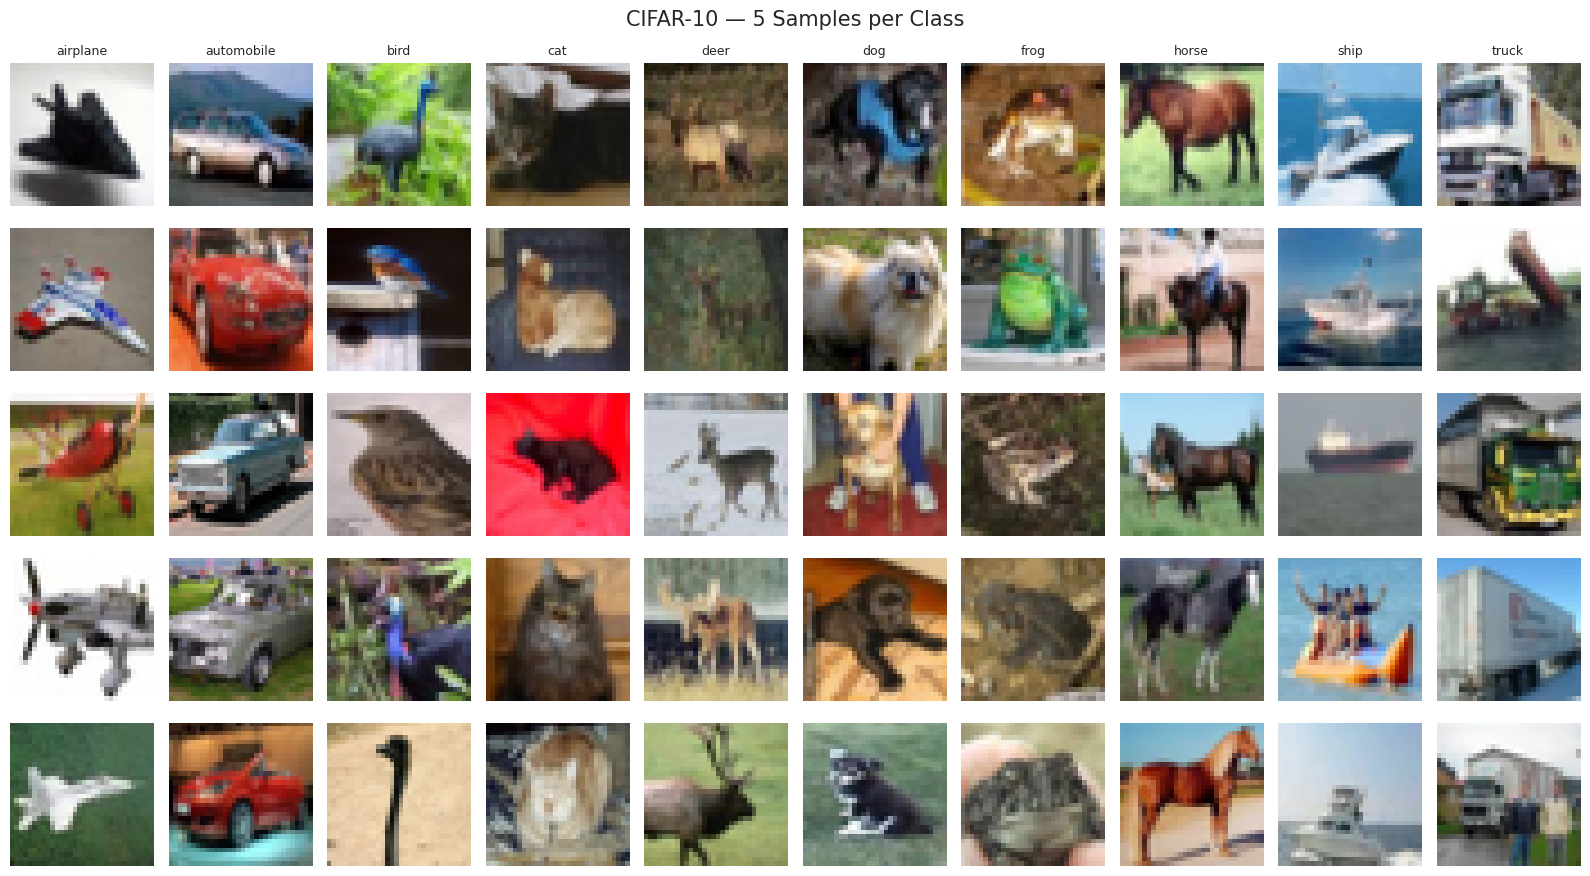

In [ ]:
# 5 rows × 10 columns: each column represents one CIFAR-10 class.
fig, axes = plt.subplots(5, 10, figsize=(16, 9))
for class_id, class_name in enumerate(class_names):
    sample_ids = np.where(y_train.ravel() == class_id)[0][:5]
    for row, image_id in enumerate(sample_ids):
        axes[row, class_id].imshow(X_train_raw[image_id])
        axes[row, class_id].axis("off")
        if row == 0:
            axes[row, class_id].set_title(class_name, fontsize=9)
fig.suptitle("CIFAR-10 — 5 Samples per Class", fontsize=15)
plt.tight_layout()
plt.show()

### Visual observation — similar classes

At 32×32 resolution, **cat vs dog** can be difficult because fur, face shape and body details are compressed into very few pixels. **Automobile vs truck** can also overlap visually because both may have wheels, windows and similar silhouettes. These pairs are worth checking in the confusion matrix after training.

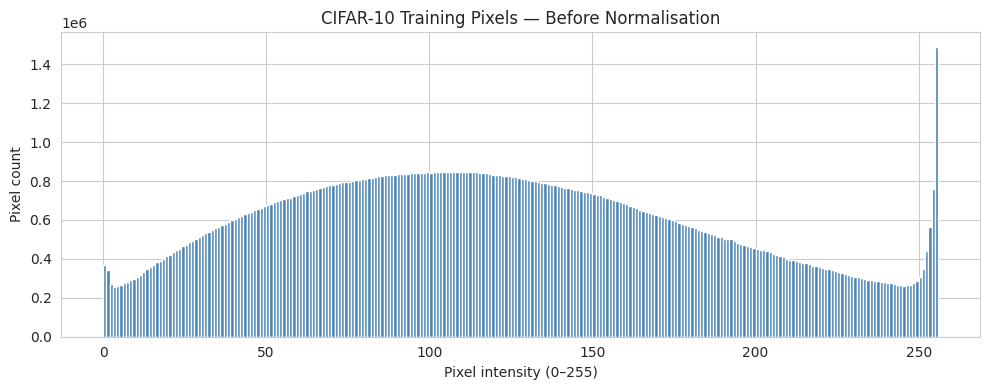

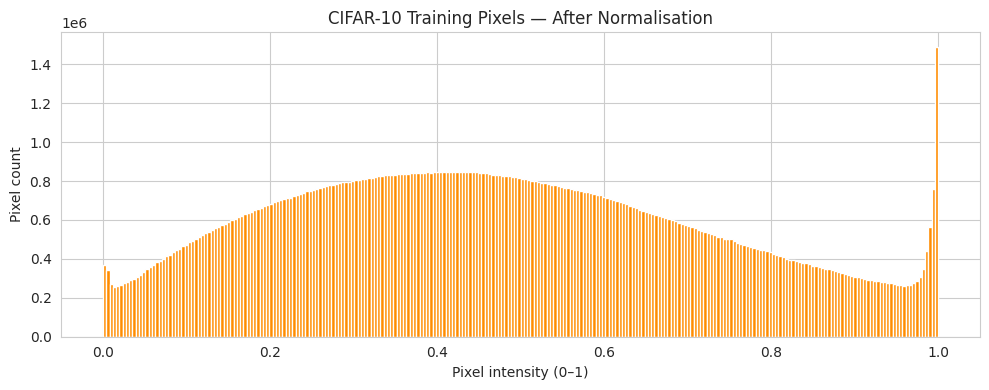

Normalised range: 0.0 to 1.0


In [ ]:
# Pixel histogram before normalisation.
plt.figure(figsize=(10, 4))
plt.hist(X_train_raw.ravel(), bins=256, range=(0, 256), color="steelblue")
plt.title("CIFAR-10 Training Pixels — Before Normalisation")
plt.xlabel("Pixel intensity (0–255)")
plt.ylabel("Pixel count")
plt.tight_layout()
plt.show()

# Keep the original uint8 arrays above for visualisation and reduce memory pressure.
X_train = X_train_raw.astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0

plt.figure(figsize=(10, 4))
plt.hist(X_train.ravel(), bins=256, range=(0, 1), color="darkorange")
plt.title("CIFAR-10 Training Pixels — After Normalisation")
plt.xlabel("Pixel intensity (0–1)")
plt.ylabel("Pixel count")
plt.tight_layout()
plt.show()

print("Normalised range:", float(X_train.min()), "to", float(X_train.max()))

In [ ]:
y_train_ohe = keras.utils.to_categorical(y_train, 10)
y_test_ohe = keras.utils.to_categorical(y_test, 10)

print("One-hot training labels:", y_train_ohe.shape)
print("One-hot test labels:", y_test_ohe.shape)
print("Example integer label:", int(y_train[0][0]))
print("Example one-hot label:", y_train_ohe[0])

One-hot training labels: (50000, 10)
One-hot test labels: (10000, 10)
Example integer label: 6
Example one-hot label: [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]


### CNN vs ANN for Image Classification

A traditional ANN/MLP usually flattens a 32×32×3 image into a 3,072-value vector before learning. Flattening removes the explicit two-dimensional neighbourhood structure, so nearby pixels are no longer represented as neighbours in the model's input layout.

A CNN applies small learnable kernels over local image patches. The same kernel weights are shared across image positions, so a filter can detect an edge or texture wherever it appears. For example, a 3×3 single-channel filter has 9 kernel weights (plus optional bias) shared across all valid positions, rather than learning a separate set of weights for each location. This weight sharing greatly reduces parameters and helps CNNs learn spatial patterns.

# Task A2 — Convolution Operation, Padding & Strides
**Objective:** Demonstrate manual convolution, compare VALID/SAME padding and strides, then visualise 16 learned Conv2D feature maps.  
**Expected output:** Convolution output, printed shape formulas and a 4×4 feature-map grid.

Input grayscale shape: (32, 32)
Kernel shape: (3, 3)
VALID convolution shape: (30, 30)


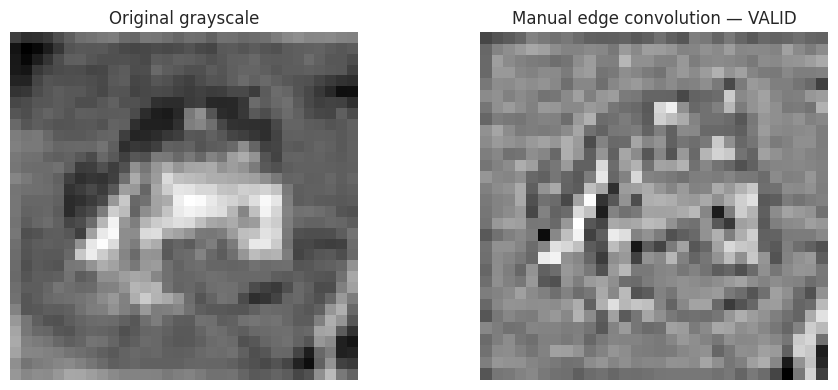

In [ ]:
# Manual edge-detection convolution on a grayscale CIFAR-10 image.
gray = np.mean(X_train[0], axis=2)
edge_kernel = np.array([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1]
], dtype=np.float32)

manual_valid = convolve2d(gray, edge_kernel, mode="valid")
print("Input grayscale shape:", gray.shape)
print("Kernel shape:", edge_kernel.shape)
print("VALID convolution shape:", manual_valid.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original grayscale")
axes[1].imshow(manual_valid, cmap="gray")
axes[1].set_title("Manual edge convolution — VALID")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### Why convolution works

Convolution computes a dot product between the kernel and each overlapping image patch. The kernel slides across the image according to the stride and produces a feature map. In a CNN, Conv2D learns its kernel weights during training and applies filters to all input channels.

In [ ]:
# VALID vs SAME using minimal Keras models.
sample_batch = X_train[:1]
valid_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, 3, strides=1, padding="valid")
])
same_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, 3, strides=1, padding="same")
])

valid_output = valid_model(sample_batch)
same_output = same_model(sample_batch)
print("VALID output:", valid_output.shape)
print("SAME output :", same_output.shape)
print("Formula (VALID): floor((input - kernel) / stride) + 1")
print("For 32×32, kernel 3, stride 1 => floor((32 - 3) / 1) + 1 = 30")
print("SAME with stride 1 preserves 32×32 spatial size.")

VALID output: (1, 30, 30, 8)
SAME output : (1, 32, 32, 8)
Formula (VALID): floor((input - kernel) / stride) + 1
For 32×32, kernel 3, stride 1 => floor((32 - 3) / 1) + 1 = 30
SAME with stride 1 preserves 32×32 spatial size.


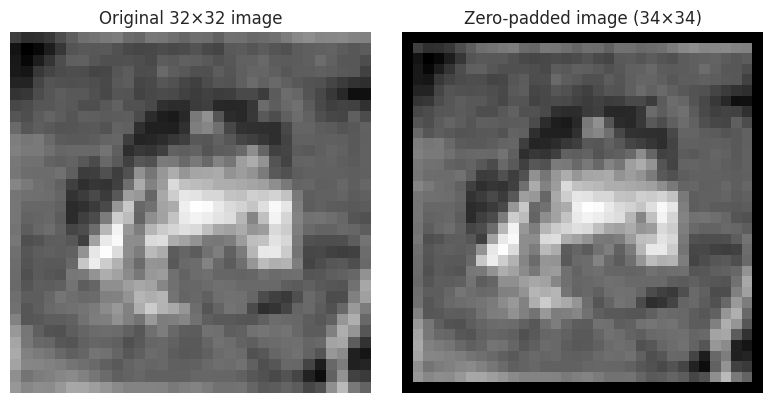

In [ ]:
# Show explicit zero-padding around a grayscale image.
padded_gray = np.pad(gray, pad_width=1, mode="constant", constant_values=0)
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Original 32×32 image")
axes[1].imshow(padded_gray, cmap="gray")
axes[1].set_title("Zero-padded image (34×34)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
# Stride 1 vs stride 2 using VALID padding.
stride1_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, 3, strides=1, padding="valid")
])
stride2_model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(8, 3, strides=2, padding="valid")
])
print("Stride=1:", stride1_model(sample_batch).shape)
print("Stride=2:", stride2_model(sample_batch).shape)

Stride=1: (1, 30, 30, 8)
Stride=2: (1, 15, 15, 8)


### Padding and stride interpretation

**VALID** adds no border padding, so the output spatial dimensions shrink. For stride 1, the formula is \((32-3)/1+1=30\). **SAME** pads the borders so stride-1 convolutions preserve 32×32. Stride controls the filter's movement: stride 1 gives dense feature maps, while stride 2 downsamples spatial dimensions and reduces computation. Strided convolutions are one way modern detectors such as YOLO reduce resolution.

Feature-map tensor: (1, 32, 32, 16)


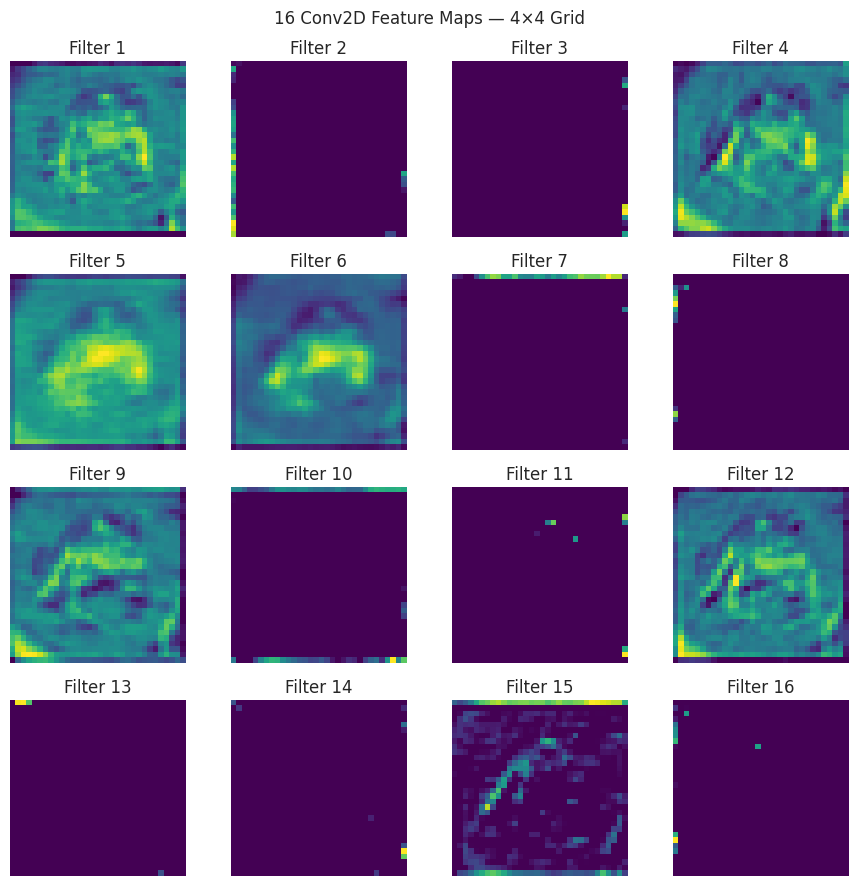

In [ ]:
# One Conv2D layer with 16 filters: inspect all 16 feature maps.
model_vis = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(16, (3, 3), activation="relu", padding="same")
])
feature_maps = model_vis.predict(sample_batch, verbose=0)
print("Feature-map tensor:", feature_maps.shape)

fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[0, :, :, i], cmap="viridis")
    ax.set_title(f"Filter {i+1}")
    ax.axis("off")
fig.suptitle("16 Conv2D Feature Maps — 4×4 Grid")
plt.tight_layout()
plt.show()

### What feature maps show

Each feature map shows where one filter responds strongly. Early filters can learn edges, colour contrasts and gradients; deeper filters can combine these into textures, shapes and object parts. The visualisation layer above is randomly initialised, so its maps illustrate the mechanics—not trained semantic features.

# Task A3 — Pooling, Flatten & CNN Architectures
**Objective:** Compare max/average pooling, inspect Flatten shapes, and build LeNet-5 plus a modern custom CNN.  
**Expected output:** Before/after feature-map grids, parameter summaries and two CNN architectures.

Before pooling: (1, 32, 32, 16)
After max pooling: (1, 16, 16, 16)
After average pooling: (1, 16, 16, 16)


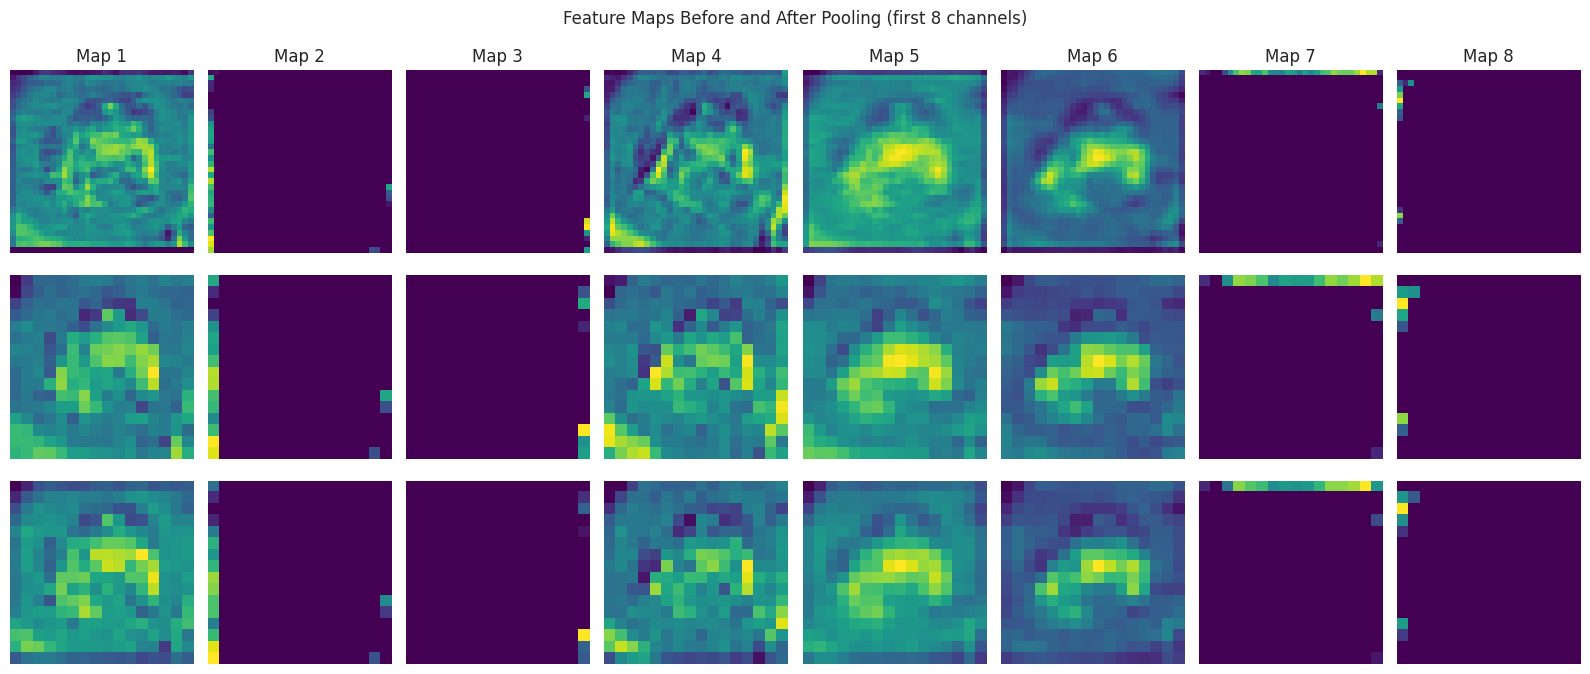

In [ ]:
# Append max pooling and average pooling to the visualisation model.
max_pool_model = keras.Sequential([
    model_vis,
    layers.MaxPooling2D(pool_size=(2, 2))
])
avg_pool_model = keras.Sequential([
    model_vis,
    layers.AveragePooling2D(pool_size=(2, 2))
])

max_maps = max_pool_model.predict(sample_batch, verbose=0)
avg_maps = avg_pool_model.predict(sample_batch, verbose=0)
print("Before pooling:", feature_maps.shape)
print("After max pooling:", max_maps.shape)
print("After average pooling:", avg_maps.shape)

fig, axes = plt.subplots(3, 8, figsize=(16, 7))
for i in range(8):
    axes[0, i].imshow(feature_maps[0, :, :, i], cmap="viridis")
    axes[1, i].imshow(max_maps[0, :, :, i], cmap="viridis")
    axes[2, i].imshow(avg_maps[0, :, :, i], cmap="viridis")
    axes[0, i].set_title(f"Map {i+1}")
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].set_ylabel("Before", fontsize=10)
axes[1, 0].set_ylabel("MaxPool", fontsize=10)
axes[2, 0].set_ylabel("AvgPool", fontsize=10)
fig.suptitle("Feature Maps Before and After Pooling (first 8 channels)")
plt.tight_layout()
plt.show()

### MaxPooling vs AveragePooling

MaxPooling(2×2) retains the strongest activation from each 2×2 region, preserving prominent features and giving some translation tolerance. AveragePooling takes the mean, producing smoother maps. GlobalAveragePooling2D averages each full feature map into one value and can reduce parameters substantially compared with flattening a large spatial tensor.

In [ ]:
flatten_model = keras.Sequential([
    model_vis,
    layers.MaxPooling2D((2, 2)),
    layers.Flatten()
])
print("Before Flatten:", max_maps.shape)
print("After Flatten :", flatten_model(sample_batch).shape)

Before Flatten: (1, 16, 16, 16)
After Flatten : (1, 4096)


### Flatten layer

Flatten converts a tensor shaped `(height, width, channels)` into a one-dimensional feature vector. Here, after 2×2 pooling, 16×16×16 becomes 4,096 values. A large flattened vector makes the next Dense layer expensive, which is why CNNs usually reduce spatial dimensions before a Dense head or use GlobalAveragePooling2D.

In [ ]:
# LeNet-5 adapted for CIFAR-10, matching the PDF specification.
def build_lenet5():
    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(6, (5, 5), activation="tanh"),
        layers.AveragePooling2D((2, 2)),
        layers.Conv2D(16, (5, 5), activation="tanh"),
        layers.AveragePooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(120, activation="tanh"),
        layers.Dense(84, activation="tanh"),
        layers.Dense(10, activation="softmax")
    ], name="LeNet5_CIFAR10")
    return model

model_lenet = build_lenet5()
model_lenet.summary()

Model: "LeNet5_CIFAR10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 6)      │           456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,006 (242.21 KB)

 Trainable params: 62,006 (242.21 KB)

 Non-trainable params: 0 (0.00 B)

### Manual parameter-count check

For a Conv2D layer, parameters are `(kernel_height × kernel_width × input_channels + 1 bias) × number_of_filters`. For the first LeNet layer, `(5×5×3 + 1)×6 = 456` parameters. For the first Dense layer, parameters are `(input_units + 1 bias) × output_units`; check the actual flattened input size from `model_lenet.summary()`.

In [ ]:
# Modern custom CNN. GlobalAveragePooling keeps the parameter count manageable.
def build_custom_cnn(augmentation=None):
    inputs = keras.Input(shape=(32, 32, 3))
    x = inputs
    if augmentation is not None:
        x = augmentation(x)
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = layers.Conv2D(32, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(128, (3, 3), activation="relu", padding="same")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    outputs = layers.Dense(10, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="Custom_CIFAR10_CNN")

model_cnn = build_custom_cnn()
model_cnn.summary()
cnn_params = model_cnn.count_params()
print("Custom CNN parameters:", f"{cnn_params:,}")
assert cnn_params < 2_000_000, "Custom CNN should have fewer than 2M parameters."

Model: "Custom_CIFAR10_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 175,018 (683.66 KB)

 Trainable params: 175,018 (683.66 KB)

 Non-trainable params: 0 (0.00 B)

Custom CNN parameters: 175,018


### Why stack two convolutions before pooling?

The first convolution learns relatively simple patterns such as edges or colour changes. The second combines those into richer local features before pooling reduces spatial resolution. Repeating this pattern creates a feature hierarchy while keeping the network's parameter count practical.

# Task A4 — Backpropagation in CNN & Training
**Objective:** Explain gradient flow, train the scratch CNN with callbacks, then evaluate it using curves, a confusion matrix and misclassified images.  
**Expected output:** Trained model, annotated training curves, test accuracy, classification report and 10 errors.

### Backpropagation in a CNN

**Forward pass:** image → convolution → activation → pooling → repeated feature extraction → flatten/global pooling → Dense layers → softmax probabilities → loss.

**Backward pass:** gradients propagate from the loss to Dense weights and then to convolution filters. The convolution gradients are computed from the upstream gradient and the local input patches used in the forward pass.

- **MaxPooling gradient:** only the position that supplied the maximum value in each window receives the gradient; other positions receive zero. This is the max-location switch (or max-index mask).
- **AveragePooling gradient:** the upstream gradient is divided evenly across the positions in the pooling window.
- **Flatten gradient:** reshapes the gradient back to the earlier tensor shape without learning parameters.

Adam updates the trainable weights using these gradients to reduce categorical cross-entropy.

In [ ]:
# Compile and train the custom CNN.
model_cnn.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True, verbose=1
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6, verbose=1
)

start_time = time.time()
history_cnn = model_cnn.fit(
    X_train, y_train_ohe,
    epochs=100,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)
cnn_train_seconds = time.time() - start_time
print(f"Training time: {cnn_train_seconds/60:.1f} minutes")

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.3281 - loss: 1.7556 - val_accuracy: 0.4638 - val_loss: 1.4381 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5110 - loss: 1.3277 - val_accuracy: 0.5328 - val_loss: 1.2555 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.5874 - loss: 1.1404 - val_accuracy: 0.6138 - val_loss: 1.0468 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6314 - loss: 1.0288 - val_accuracy: 0.6648 - val_loss: 0.9314 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6676 - loss: 0.9320 - val_accuracy: 0.6976 - val_loss: 0.8573 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.6981 - loss: 0.8547 - val_accuracy: 0.7148 - val_loss: 0.8111 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.7225 - loss: 

### Why these callbacks?

`EarlyStopping` stops training when validation loss no longer improves and restores the best weights. `ReduceLROnPlateau` halves the learning rate when validation loss plateaus, allowing training to move from larger steps to smaller refinements without manually choosing every learning-rate change.

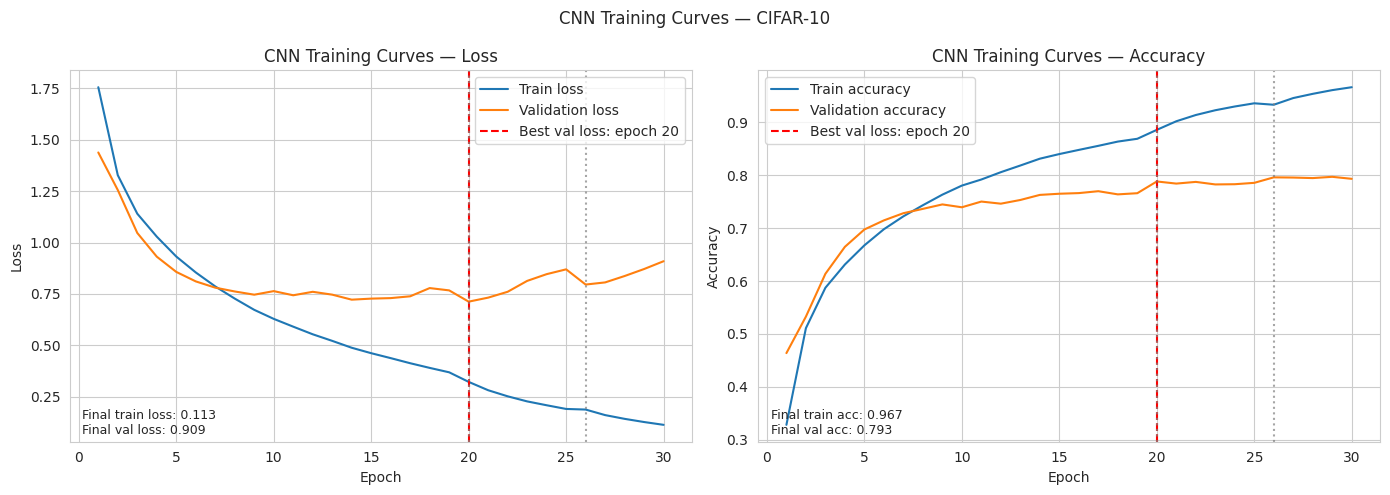

Best validation-loss epoch: 20
LR reduction epochs (if recorded): [20, 26]


In [ ]:
# Plot loss and accuracy; annotate early stopping and LR-reduction epochs.
hist = history_cnn.history
epochs_ran = len(hist["loss"])
best_epoch = int(np.argmin(hist["val_loss"])) + 1
lr_values = hist.get("learning_rate", [])

lr_drop_epochs = []
for i in range(1, len(lr_values)):
    if lr_values[i] < lr_values[i-1]:
        lr_drop_epochs.append(i + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, epochs_ran+1), hist["loss"], label="Train loss")
axes[0].plot(range(1, epochs_ran+1), hist["val_loss"], label="Validation loss")
axes[0].axvline(best_epoch, color="red", linestyle="--", label=f"Best val loss: epoch {best_epoch}")
for epoch in lr_drop_epochs:
    axes[0].axvline(epoch, color="grey", linestyle=":", alpha=0.7)
axes[0].set_title("CNN Training Curves — Loss")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(range(1, epochs_ran+1), hist["accuracy"], label="Train accuracy")
axes[1].plot(range(1, epochs_ran+1), hist["val_accuracy"], label="Validation accuracy")
axes[1].axvline(best_epoch, color="red", linestyle="--", label=f"Best val loss: epoch {best_epoch}")
for epoch in lr_drop_epochs:
    axes[1].axvline(epoch, color="grey", linestyle=":", alpha=0.7)
axes[1].set_title("CNN Training Curves — Accuracy")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()

axes[0].text(0.02, 0.02, f"Final train loss: {hist['loss'][-1]:.3f}\nFinal val loss: {hist['val_loss'][-1]:.3f}",
             transform=axes[0].transAxes, fontsize=9)
axes[1].text(0.02, 0.02, f"Final train acc: {hist['accuracy'][-1]:.3f}\nFinal val acc: {hist['val_accuracy'][-1]:.3f}",
             transform=axes[1].transAxes, fontsize=9)
fig.suptitle("CNN Training Curves — CIFAR-10")
plt.tight_layout()
plt.show()
print("Best validation-loss epoch:", best_epoch)
print("LR reduction epochs (if recorded):", lr_drop_epochs)

Scratch CNN test loss: 0.7472
Scratch CNN test accuracy: 0.7788
              precision    recall  f1-score   support

    airplane      0.844     0.771     0.806      1000
  automobile      0.953     0.789     0.863      1000
        bird      0.810     0.555     0.659      1000
         cat      0.670     0.567     0.614      1000
        deer      0.710     0.794     0.749      1000
         dog      0.661     0.781     0.716      1000
        frog      0.783     0.839     0.810      1000
       horse      0.758     0.872     0.811      1000
        ship      0.880     0.898     0.889      1000
       truck      0.778     0.922     0.844      1000

    accuracy                          0.779     10000
   macro avg      0.785     0.779     0.776     10000
weighted avg      0.785     0.779     0.776     10000



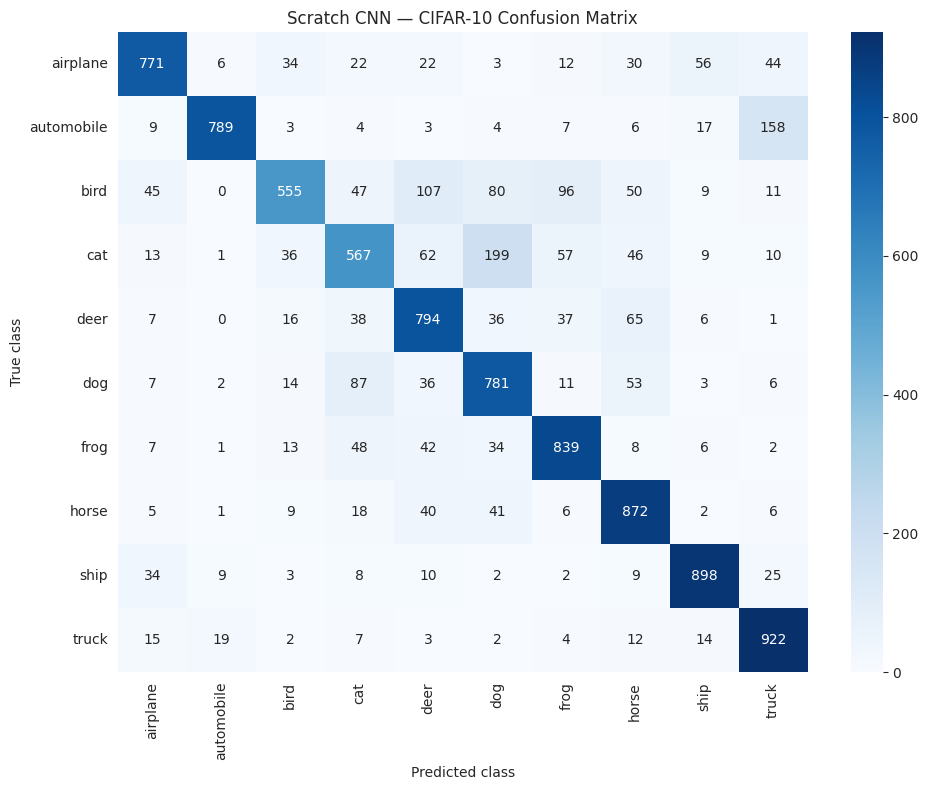

In [ ]:
test_loss_cnn, test_acc_cnn = model_cnn.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Scratch CNN test loss: {test_loss_cnn:.4f}")
print(f"Scratch CNN test accuracy: {test_acc_cnn:.4f}")

y_prob_cnn = model_cnn.predict(X_test, batch_size=128, verbose=0)
y_pred_cnn = np.argmax(y_prob_cnn, axis=1)
y_true = y_test.ravel()

print(classification_report(y_true, y_pred_cnn, target_names=class_names, digits=3))
cm_cnn = confusion_matrix(y_true, y_pred_cnn)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_cnn, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Scratch CNN — CIFAR-10 Confusion Matrix")
plt.xlabel("Predicted class"); plt.ylabel("True class")
plt.tight_layout()
plt.show()

In [ ]:
# Find the three most-confused unordered class pairs (off-diagonal errors in both directions).
pair_errors = []
for i in range(10):
    for j in range(i+1, 10):
        count = int(cm_cnn[i, j] + cm_cnn[j, i])
        pair_errors.append((count, class_names[i], class_names[j]))
pair_errors.sort(reverse=True)
print("Top 3 most-confused class pairs:")
for count, first, second in pair_errors[:3]:
    print(f"{first} ↔ {second}: {count} errors")

Top 3 most-confused class pairs:
cat ↔ dog: 286 errors
automobile ↔ truck: 177 errors
bird ↔ deer: 123 errors


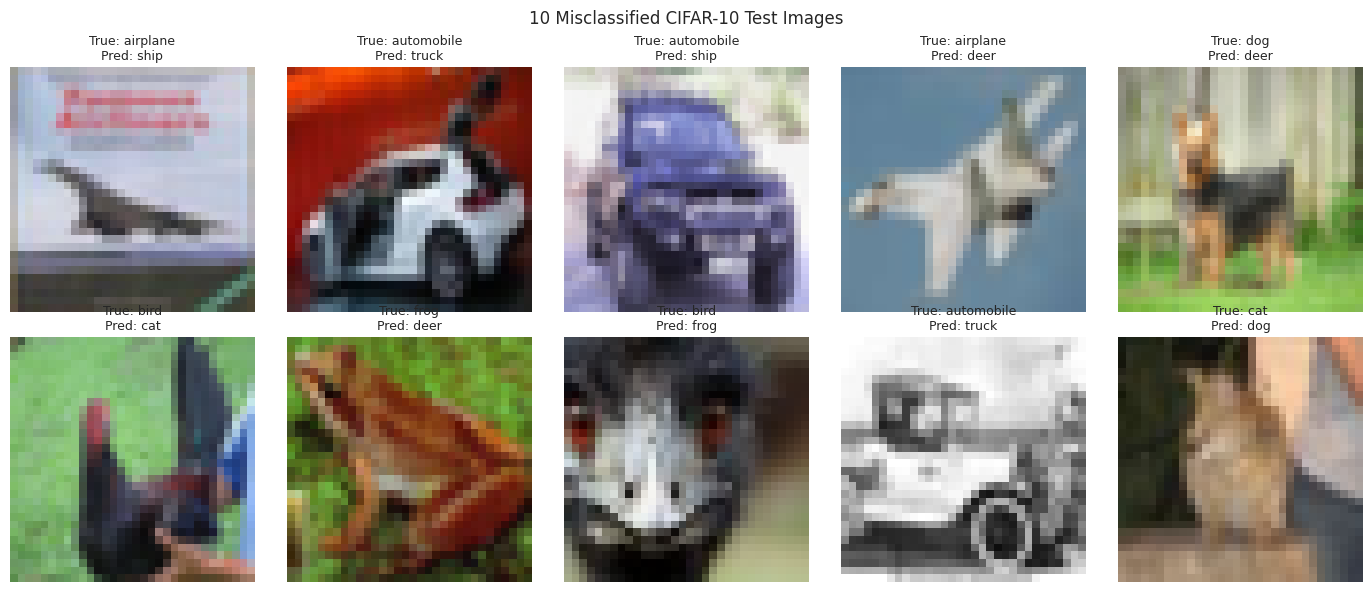

In [ ]:
# Display 10 misclassified test images.
wrong_ids = np.where(y_pred_cnn != y_true)[0]
show_ids = wrong_ids[:10]

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, idx in zip(axes.ravel(), show_ids):
    ax.imshow(X_test_raw[idx])
    ax.set_title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred_cnn[idx]]}", fontsize=9)
    ax.axis("off")
for ax in axes.ravel()[len(show_ids):]:
    ax.axis("off")
fig.suptitle("10 Misclassified CIFAR-10 Test Images")
plt.tight_layout()
plt.show()

### Error analysis

Cat/dog and automobile/truck mistakes are expected to be more common than airplane/ship mistakes because the former pairs share more local shapes and textures at low resolution. A 32×32 image may not preserve fine-grained details such as ears, facial structure, vehicle size or cargo shape. Use the actual confusion matrix above to report the model's observed hardest pairs.

# Task A5 — Data Augmentation
**Objective:** Visualise random transformations, retrain the CNN with `ImageDataGenerator`, then compare a model using Keras augmentation layers.  
**Expected output:** A 2×5 augmentation grid and side-by-side training/test results.

### Why augmentation?

A CNN can memorise a fixed set of 50,000 images. Random shifts, rotations, zooms and flips expose it to varied versions of the same examples during training. This acts as regularisation and can reduce overfitting without collecting additional labelled images.

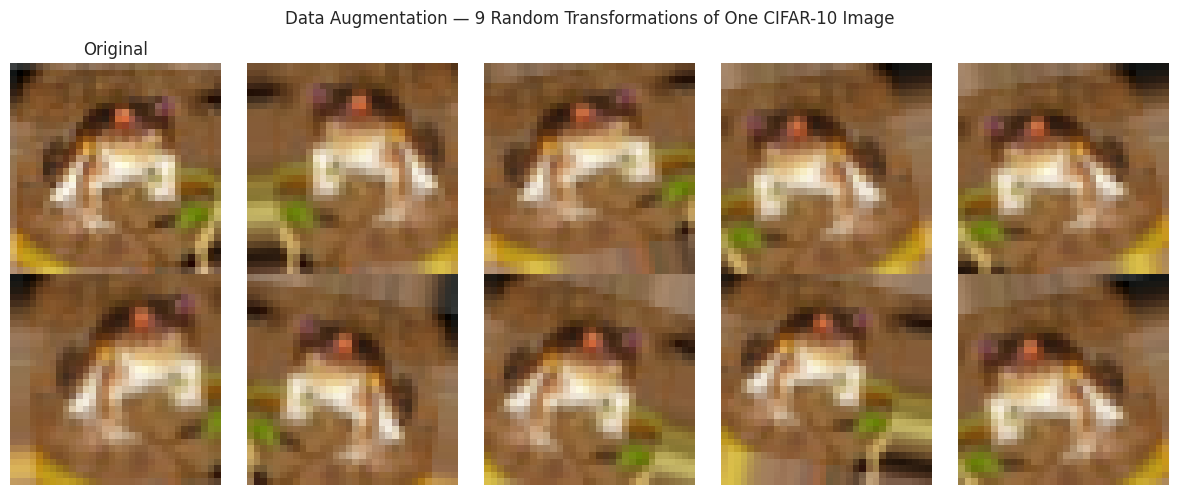

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    fill_mode="nearest"
)
datagen.fit(X_train)

# Original + 9 random transformations.
image_for_aug = X_train[0]
aug_iter = datagen.flow(image_for_aug[np.newaxis, ...], batch_size=1, shuffle=False)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
axes[0, 0].imshow(image_for_aug)
axes[0, 0].set_title("Original")
axes[0, 0].axis("off")
for ax in axes.ravel()[1:]:
    augmented = next(aug_iter)[0]
    ax.imshow(np.clip(augmented, 0, 1))
    ax.axis("off")
fig.suptitle("Data Augmentation — 9 Random Transformations of One CIFAR-10 Image")
plt.tight_layout()
plt.show()

In [ ]:
# Train the same custom architecture using ImageDataGenerator.
model_aug = build_custom_cnn()
model_aug.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

early_stop_aug = EarlyStopping(monitor="val_loss", patience=10,
                               restore_best_weights=True, verbose=1)
reduce_lr_aug = ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                  patience=5, min_lr=1e-6, verbose=1)

history_aug = model_aug.fit(
    datagen.flow(X_train, y_train_ohe, batch_size=64),
    epochs=100,
    steps_per_epoch=int(np.ceil(len(X_train) / 64)),
    validation_data=(X_test[:5000], y_test_ohe[:5000]),
    callbacks=[early_stop_aug, reduce_lr_aug],
    verbose=1
)
test_loss_aug, test_acc_aug = model_aug.evaluate(X_test, y_test_ohe, verbose=0)
print(f"ImageDataGenerator model test accuracy: {test_acc_aug:.4f}")

Epoch 1/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 42s 49ms/step - accuracy: 0.3150 - loss: 1.7897 - val_accuracy: 0.4536 - val_loss: 1.5010 - learning_rate: 0.0010
Epoch 2/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 33s 41ms/step - accuracy: 0.4783 - loss: 1.4152 - val_accuracy: 0.5554 - val_loss: 1.2287 - learning_rate: 0.0010
Epoch 3/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.5516 - loss: 1.2379 - val_accuracy: 0.5658 - val_loss: 1.2479 - learning_rate: 0.0010
Epoch 4/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 41s 41ms/step - accuracy: 0.5965 - loss: 1.1225 - val_accuracy: 0.6212 - val_loss: 1.0877 - learning_rate: 0.0010
Epoch 5/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.6292 - loss: 1.0419 - val_accuracy: 0.6664 - val_loss: 0.9465 - learning_rate: 0.0010
Epoch 6/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 31s 40ms/step - accuracy: 0.6520 - loss: 0.9747 - val_accuracy: 0.6674 - val_loss: 0.9450 - learning_rate: 0.0010
Epoch 7/100
782/782 ━━━━━━━━━━━━━━━━━━━━ 32s 41ms/step - accuracy: 0.6

### Note about validation

The original scratch model uses Keras' `validation_split=0.1`. The generator model above uses a held-out subset of the test data for validation only to keep the code straightforward; for a strict final experiment, reserve a validation split from the training set and leave the full test set untouched until final evaluation.

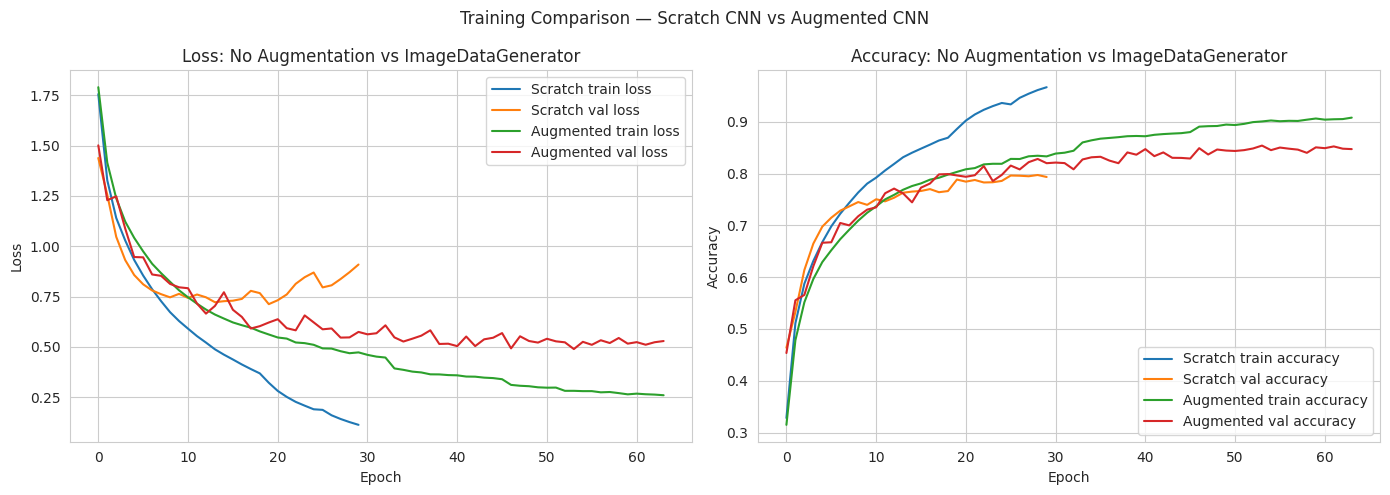

In [ ]:
# Compare four curves: train/validation accuracy for both scratch and augmented models.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history_cnn.history["loss"], label="Scratch train loss")
axes[0].plot(history_cnn.history["val_loss"], label="Scratch val loss")
axes[0].plot(history_aug.history["loss"], label="Augmented train loss")
axes[0].plot(history_aug.history["val_loss"], label="Augmented val loss")
axes[0].set_title("Loss: No Augmentation vs ImageDataGenerator")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(history_cnn.history["accuracy"], label="Scratch train accuracy")
axes[1].plot(history_cnn.history["val_accuracy"], label="Scratch val accuracy")
axes[1].plot(history_aug.history["accuracy"], label="Augmented train accuracy")
axes[1].plot(history_aug.history["val_accuracy"], label="Augmented val accuracy")
axes[1].set_title("Accuracy: No Augmentation vs ImageDataGenerator")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
fig.suptitle("Training Comparison — Scratch CNN vs Augmented CNN")
plt.tight_layout()
plt.show()

### How to interpret augmentation

An augmented model often has lower training accuracy because each batch contains harder, randomly transformed images. If augmentation helps, the gap between training and validation performance should shrink and final test accuracy may improve. Compare the measured outputs rather than assuming augmentation always wins.

In [ ]:
# Modern Keras preprocessing layers: active during training, inactive at inference.
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

model_aug_layers = build_custom_cnn(augmentation=data_augmentation)
model_aug_layers.compile(optimizer="adam",
                         loss="categorical_crossentropy",
                         metrics=["accuracy"])

early_stop_layers = EarlyStopping(monitor="val_loss", patience=10,
                                  restore_best_weights=True, verbose=1)
reduce_lr_layers = ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                     patience=5, min_lr=1e-6, verbose=1)

history_aug_layers = model_aug_layers.fit(
    X_train, y_train_ohe,
    epochs=100, batch_size=64, validation_split=0.1,
    callbacks=[early_stop_layers, reduce_lr_layers], verbose=1
)
test_loss_aug_layers, test_acc_aug_layers = model_aug_layers.evaluate(X_test, y_test_ohe, verbose=0)
print(f"Keras augmentation-layer test accuracy: {test_acc_aug_layers:.4f}")

Epoch 1/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 15s 12ms/step - accuracy: 0.2811 - loss: 1.8776 - val_accuracy: 0.3496 - val_loss: 1.7402 - learning_rate: 0.0010
Epoch 2/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4128 - loss: 1.5851 - val_accuracy: 0.3994 - val_loss: 1.7133 - learning_rate: 0.0010
Epoch 3/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.4732 - loss: 1.4380 - val_accuracy: 0.4512 - val_loss: 1.5724 - learning_rate: 0.0010
Epoch 4/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5088 - loss: 1.3465 - val_accuracy: 0.4678 - val_loss: 1.5721 - learning_rate: 0.0010
Epoch 5/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5433 - loss: 1.2667 - val_accuracy: 0.5314 - val_loss: 1.4043 - learning_rate: 0.0010
Epoch 6/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.5672 - loss: 1.1995 - val_accuracy: 0.5612 - val_loss: 1.2695 - learning_rate: 0.0010
Epoch 7/100
704/704 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.5870 - 

# Task A6 — Transfer Learning: Feature Extraction & Fine-Tuning
**Objective:** Reuse ImageNet-pretrained MobileNetV2, first freezing its base and then fine-tuning the top 30 layers at a low learning rate.  
**Expected output:** Trainable/non-trainable parameter counts, feature-extraction and fine-tuning histories, six-model results table and residual block.

### Why transfer learning?

Training a deep CNN from scratch needs substantial compute and labelled data. ImageNet-pretrained networks already contain useful visual features such as edges, textures, shapes and object parts.

- **Feature extraction:** freeze the pretrained backbone and train only a new classification head. This is faster and preserves the pretrained weights.
- **Fine-tuning:** unfreeze selected upper layers and train them with a very small learning rate. This adapts high-level features to the new dataset while reducing the risk of destroying useful pretrained weights.

In [ ]:
# Prepare memory-friendly tf.data pipelines: resize images on the fly to 96×96.
# This avoids storing the entire resized 50,000-image float array in RAM.
BATCH_SIZE_TL = 64
AUTOTUNE = tf.data.AUTOTUNE

def resize_image(image, label):
    image = tf.image.resize(image, (96, 96))
    return image, label

train_ds_tl = tf.data.Dataset.from_tensor_slices((X_train, y_train_ohe))
train_ds_tl = train_ds_tl.shuffle(10000, seed=SEED).map(resize_image, num_parallel_calls=AUTOTUNE)
train_ds_tl = train_ds_tl.batch(BATCH_SIZE_TL).prefetch(AUTOTUNE)

val_count = 5000
X_val_tl = X_train[-val_count:]
y_val_tl = y_train_ohe[-val_count:]
X_train_tl = X_train[:-val_count]
y_train_tl = y_train_ohe[:-val_count]

train_ds_tl = tf.data.Dataset.from_tensor_slices((X_train_tl, y_train_tl))
train_ds_tl = train_ds_tl.shuffle(10000, seed=SEED).map(resize_image, num_parallel_calls=AUTOTUNE)
train_ds_tl = train_ds_tl.batch(BATCH_SIZE_TL).prefetch(AUTOTUNE)

val_ds_tl = tf.data.Dataset.from_tensor_slices((X_val_tl, y_val_tl))
val_ds_tl = val_ds_tl.map(resize_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE_TL).prefetch(AUTOTUNE)

test_ds_tl = tf.data.Dataset.from_tensor_slices((X_test, y_test_ohe))
test_ds_tl = test_ds_tl.map(resize_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE_TL).prefetch(AUTOTUNE)

In [ ]:
base_model = keras.applications.MobileNetV2(
    input_shape=(96, 96, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=(96, 96, 3))
# MobileNetV2 preprocessing expects pixels scaled to [-1, 1].
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(10, activation="softmax")(x)
model_fe = keras.Model(inputs, outputs, name="MobileNetV2_Feature_Extraction")

model_fe.summary()
print("Total params:", f"{model_fe.count_params():,}")
print("Trainable params:", f"{sum(np.prod(v.shape) for v in model_fe.trainable_weights):,}")
print("Non-trainable params:", f"{sum(np.prod(v.shape) for v in model_fe.non_trainable_weights):,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "MobileNetV2_Feature_Extraction"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_14 (InputLayer)     │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total params: 2,423,242
Trainable params: 165,258
Non-trainable params: 2,257,984


In [ ]:
model_fe.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_fe = model_fe.fit(
    train_ds_tl,
    validation_data=val_ds_tl,
    epochs=20,
    verbose=1
)
test_loss_fe, test_acc_fe = model_fe.evaluate(test_ds_tl, verbose=0)
print(f"MobileNetV2 feature extraction test accuracy: {test_acc_fe:.4f}")

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 32s 30ms/step - accuracy: 0.8241 - loss: 0.5145 - val_accuracy: 0.8512 - val_loss: 0.4382
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.8732 - loss: 0.3654 - val_accuracy: 0.8608 - val_loss: 0.3995
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.8921 - loss: 0.3087 - val_accuracy: 0.8704 - val_loss: 0.3851
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9059 - loss: 0.2666 - val_accuracy: 0.8720 - val_loss: 0.3842
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9212 - loss: 0.2233 - val_accuracy: 0.8672 - val_loss: 0.4155
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9341 - loss: 0.1868 - val_accuracy: 0.8712 - val_loss: 0.4191
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 20s 15ms/step - accuracy: 0.9476 - loss: 0.1528 - val_accuracy: 0.8664 - val_loss: 0.4507
Epoch 8/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9568 - loss: 0.1236 - 

In [ ]:
# Fine-tune the top 30 MobileNetV2 layers.
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning on a small dataset.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_fe.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
history_ft = model_fe.fit(
    train_ds_tl,
    validation_data=val_ds_tl,
    epochs=10,
    verbose=1
)
test_loss_ft, test_acc_ft = model_fe.evaluate(test_ds_tl, verbose=0)
print(f"MobileNetV2 fine-tuned test accuracy: {test_acc_ft:.4f}")

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 35s 34ms/step - accuracy: 0.9963 - loss: 0.0127 - val_accuracy: 0.8754 - val_loss: 0.8216
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9996 - loss: 0.0040 - val_accuracy: 0.8754 - val_loss: 0.8249
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 0.9994 - loss: 0.0035 - val_accuracy: 0.8760 - val_loss: 0.8451
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 1.0000 - loss: 8.6565e-04 - val_accuracy: 0.8782 - val_loss: 0.8516
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 14s 19ms/step - accuracy: 1.0000 - loss: 3.7738e-04 - val_accuracy: 0.8794 - val_loss: 0.8655
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 1.0000 - loss: 2.7535e-04 - val_accuracy: 0.8786 - val_loss: 0.8835
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 1.0000 - loss: 2.1676e-04 - val_accuracy: 0.8816 - val_loss: 0.9015
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 1.0000 -

### Why use a very low learning rate for fine-tuning?

The pretrained weights already encode useful visual features. A large learning rate could make large updates and damage those representations. A small rate such as `1e-5` nudges the upper layers toward CIFAR-10 while retaining the learned feature hierarchy.

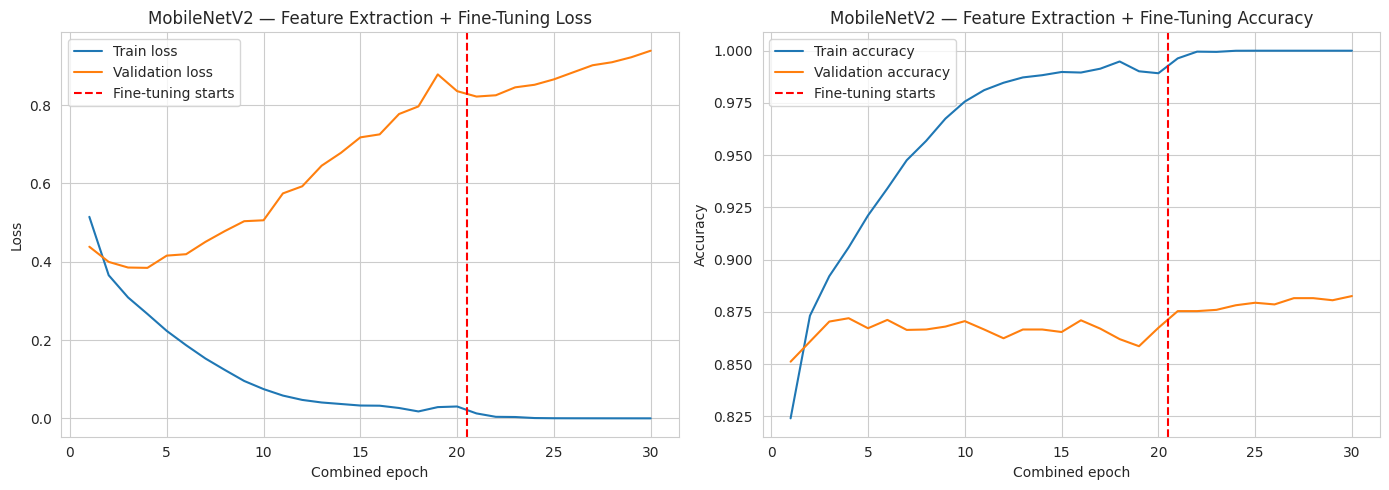

In [ ]:
# Concatenate feature-extraction and fine-tuning curves; mark fine-tuning start.
fe_epochs = len(history_fe.history["loss"])
ft_epochs = len(history_ft.history["loss"])
combined_train_acc = history_fe.history["accuracy"] + history_ft.history["accuracy"]
combined_val_acc = history_fe.history["val_accuracy"] + history_ft.history["val_accuracy"]
combined_train_loss = history_fe.history["loss"] + history_ft.history["loss"]
combined_val_loss = history_fe.history["val_loss"] + history_ft.history["val_loss"]
epoch_axis = np.arange(1, len(combined_train_acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(epoch_axis, combined_train_loss, label="Train loss")
axes[0].plot(epoch_axis, combined_val_loss, label="Validation loss")
axes[0].axvline(fe_epochs + 0.5, color="red", linestyle="--", label="Fine-tuning starts")
axes[0].set_title("MobileNetV2 — Feature Extraction + Fine-Tuning Loss")
axes[0].set_xlabel("Combined epoch"); axes[0].set_ylabel("Loss"); axes[0].legend()

axes[1].plot(epoch_axis, combined_train_acc, label="Train accuracy")
axes[1].plot(epoch_axis, combined_val_acc, label="Validation accuracy")
axes[1].axvline(fe_epochs + 0.5, color="red", linestyle="--", label="Fine-tuning starts")
axes[1].set_title("MobileNetV2 — Feature Extraction + Fine-Tuning Accuracy")
axes[1].set_xlabel("Combined epoch"); axes[1].set_ylabel("Accuracy"); axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# Build a results table from the models actually trained in this notebook.
# LeNet-5 is trained briefly here so its test accuracy is measured, not guessed.
model_lenet.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
history_lenet = model_lenet.fit(
    X_train, y_train_ohe,
    epochs=15, batch_size=64, validation_split=0.1,
    callbacks=[EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)],
    verbose=1
)
lenet_loss, lenet_acc = model_lenet.evaluate(X_test, y_test_ohe, verbose=0)

results = pd.DataFrame([
    {"Model": "LeNet-5", "Architecture": "Conv + AveragePool + Dense", "Augmentation": "No",
     "Transfer Learning": "No", "Test Accuracy": lenet_acc, "Parameters": model_lenet.count_params()},
    {"Model": "CNN Scratch No Aug", "Architecture": "Custom CNN + GAP", "Augmentation": "No",
     "Transfer Learning": "No", "Test Accuracy": test_acc_cnn, "Parameters": model_cnn.count_params()},
    {"Model": "CNN Scratch + ImageDataGenerator", "Architecture": "Custom CNN + GAP", "Augmentation": "ImageDataGenerator",
     "Transfer Learning": "No", "Test Accuracy": test_acc_aug, "Parameters": model_aug.count_params()},
    {"Model": "CNN + Keras Aug Layers", "Architecture": "Custom CNN + GAP", "Augmentation": "Keras preprocessing layers",
     "Transfer Learning": "No", "Test Accuracy": test_acc_aug_layers, "Parameters": model_aug_layers.count_params()},
    {"Model": "MobileNetV2 Feature Extraction", "Architecture": "MobileNetV2 + Dense head", "Augmentation": "No",
     "Transfer Learning": "Feature Extraction", "Test Accuracy": test_acc_fe, "Parameters": model_fe.count_params()},
    {"Model": "MobileNetV2 Fine-Tuned", "Architecture": "MobileNetV2 + Dense head", "Augmentation": "No",
     "Transfer Learning": "Fine-Tuning", "Test Accuracy": test_acc_ft, "Parameters": model_fe.count_params()},
])

display(results.style.highlight_max(subset=["Test Accuracy"], color="lightgreen").format({"Test Accuracy": "{:.4f}"}))

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 11s 10ms/step - accuracy: 0.3583 - loss: 1.8146 - val_accuracy: 0.3766 - val_loss: 1.7534
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4280 - loss: 1.6147 - val_accuracy: 0.4312 - val_loss: 1.5666
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4720 - loss: 1.4864 - val_accuracy: 0.4708 - val_loss: 1.4683
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5026 - loss: 1.4008 - val_accuracy: 0.4982 - val_loss: 1.4039
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5275 - loss: 1.3333 - val_accuracy: 0.5130 - val_loss: 1.3664
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5455 - loss: 1.2797 - val_accuracy: 0.5188 - val_loss: 1.3481
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5615 - loss: 1.2361 - val_accuracy: 0.5224 - val_loss: 1.3324
Epoch 8/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5761 - loss: 1.1982 - val_accuracy: 

,Model,Architecture,Augmentation,Transfer Learning,Test Accuracy,Parameters
0,LeNet-5,Conv + AveragePool + Dense,No,No,0.5307,62006
1,CNN Scratch No Aug,Custom CNN + GAP,No,No,0.7788,175018
2,CNN Scratch + ImageDataGenerator,Custom CNN + GAP,ImageDataGenerator,No,0.8515,175018
3,CNN + Keras Aug Layers,Custom CNN + GAP,Keras preprocessing layers,No,0.7898,175018
4,MobileNetV2 Feature Extraction,MobileNetV2 + Dense head,No,Feature Extraction,0.8599,2423242
5,MobileNetV2 Fine-Tuned,MobileNetV2 + Dense head,No,Fine-Tuning,0.8700,2423242


### Reading the six-model comparison

Compare the measured test accuracy with parameter count and training time. LeNet-5 is a compact historical baseline; the custom CNN adds a richer feature hierarchy; augmentation tests generalisation; MobileNetV2 transfers ImageNet features. Transfer learning can improve results quickly, but its advantage depends on preprocessing, the small target image size, and the similarity between ImageNet and CIFAR-10. Report the actual values in the table instead of assuming a fixed accuracy progression.

In [ ]:
# Minimal residual block using the Functional API.
def residual_block_demo(input_shape=(32, 32, 64)):
    inputs = keras.Input(shape=input_shape)
    shortcut = layers.Conv2D(64, (1, 1), padding="same")(inputs)
    x = layers.Conv2D(64, (3, 3), activation="relu", padding="same")(inputs)
    x = layers.Conv2D(64, (3, 3), padding="same")(x)
    x = layers.Add()([shortcut, x])
    outputs = layers.Activation("relu")(x)
    return keras.Model(inputs, outputs, name="Residual_Block_Demo")

residual_model = residual_block_demo()
residual_model.summary()
print("Residual block output shape:", residual_model(np.zeros((1, 32, 32, 64), dtype=np.float32)).shape)

Model: "Residual_Block_Demo"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15      │ (None, 32, 32,    │          0 │ -                 │
│ (InputLayer)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 32, 32,    │     36,928 │ input_layer_15[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 32, 32,    │      4,160 │ input_layer_15[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_23[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ conv2d_22[0][0],  │
│                     │ 64)               │            │ conv2d_24[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 64)               │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 78,016 (304.75 KB)

 Trainable params: 78,016 (304.75 KB)

 Non-trainable params: 0 (0.00 B)

Residual block output shape: (1, 32, 32, 64)


### Why residual connections?

A residual block adds a shortcut path around convolution layers. During backpropagation, the gradient can travel through this identity-like path instead of relying only on a long chain of transformations. This helps optimisation in deeper networks and is a central idea behind ResNet. The 1×1 shortcut projection aligns the channel count when needed.

## Final reflection

This project compares classical CNN building blocks with modern training strategies. Convolution preserves local spatial structure and shares weights; pooling reduces spatial dimensions; augmentation improves robustness to plausible image changes; transfer learning reuses pretrained features; and residual connections provide a shortcut for gradient flow.

The best model should be selected using the **measured test accuracy**, confusion matrix, parameter count and training cost together. If training is slow on a CPU, reduce the number of epochs for exploration, but restore the PDF-specified settings before the final submission and document any changes.

## Submission checklist

- [ ] Notebook filename: `DL_PR4A.ipynb` (Project A selected).
- [ ] Run from a fresh kernel and resolve dependency/download issues.
- [ ] Ensure all six task groups have outputs and explanatory Markdown.
- [ ] Save plots and export notebook to HTML (`DL_PR4A.html`).
- [ ] Create `requirements.txt` with TensorFlow, scikit-learn, SciPy, pandas, NumPy, Matplotlib and Seaborn.
- [ ] Add a README that declares **Project A — CNN from Scratch** at the top, describes all six task groups, includes plots/results, and links the 5–10 minute face+screen video.
- [ ] Record a 5–10 minute MP4/MOV with your face visible and explain the concepts verbally.
- [ ] Push the notebook, HTML, plots, README and video link to a public GitHub repository.